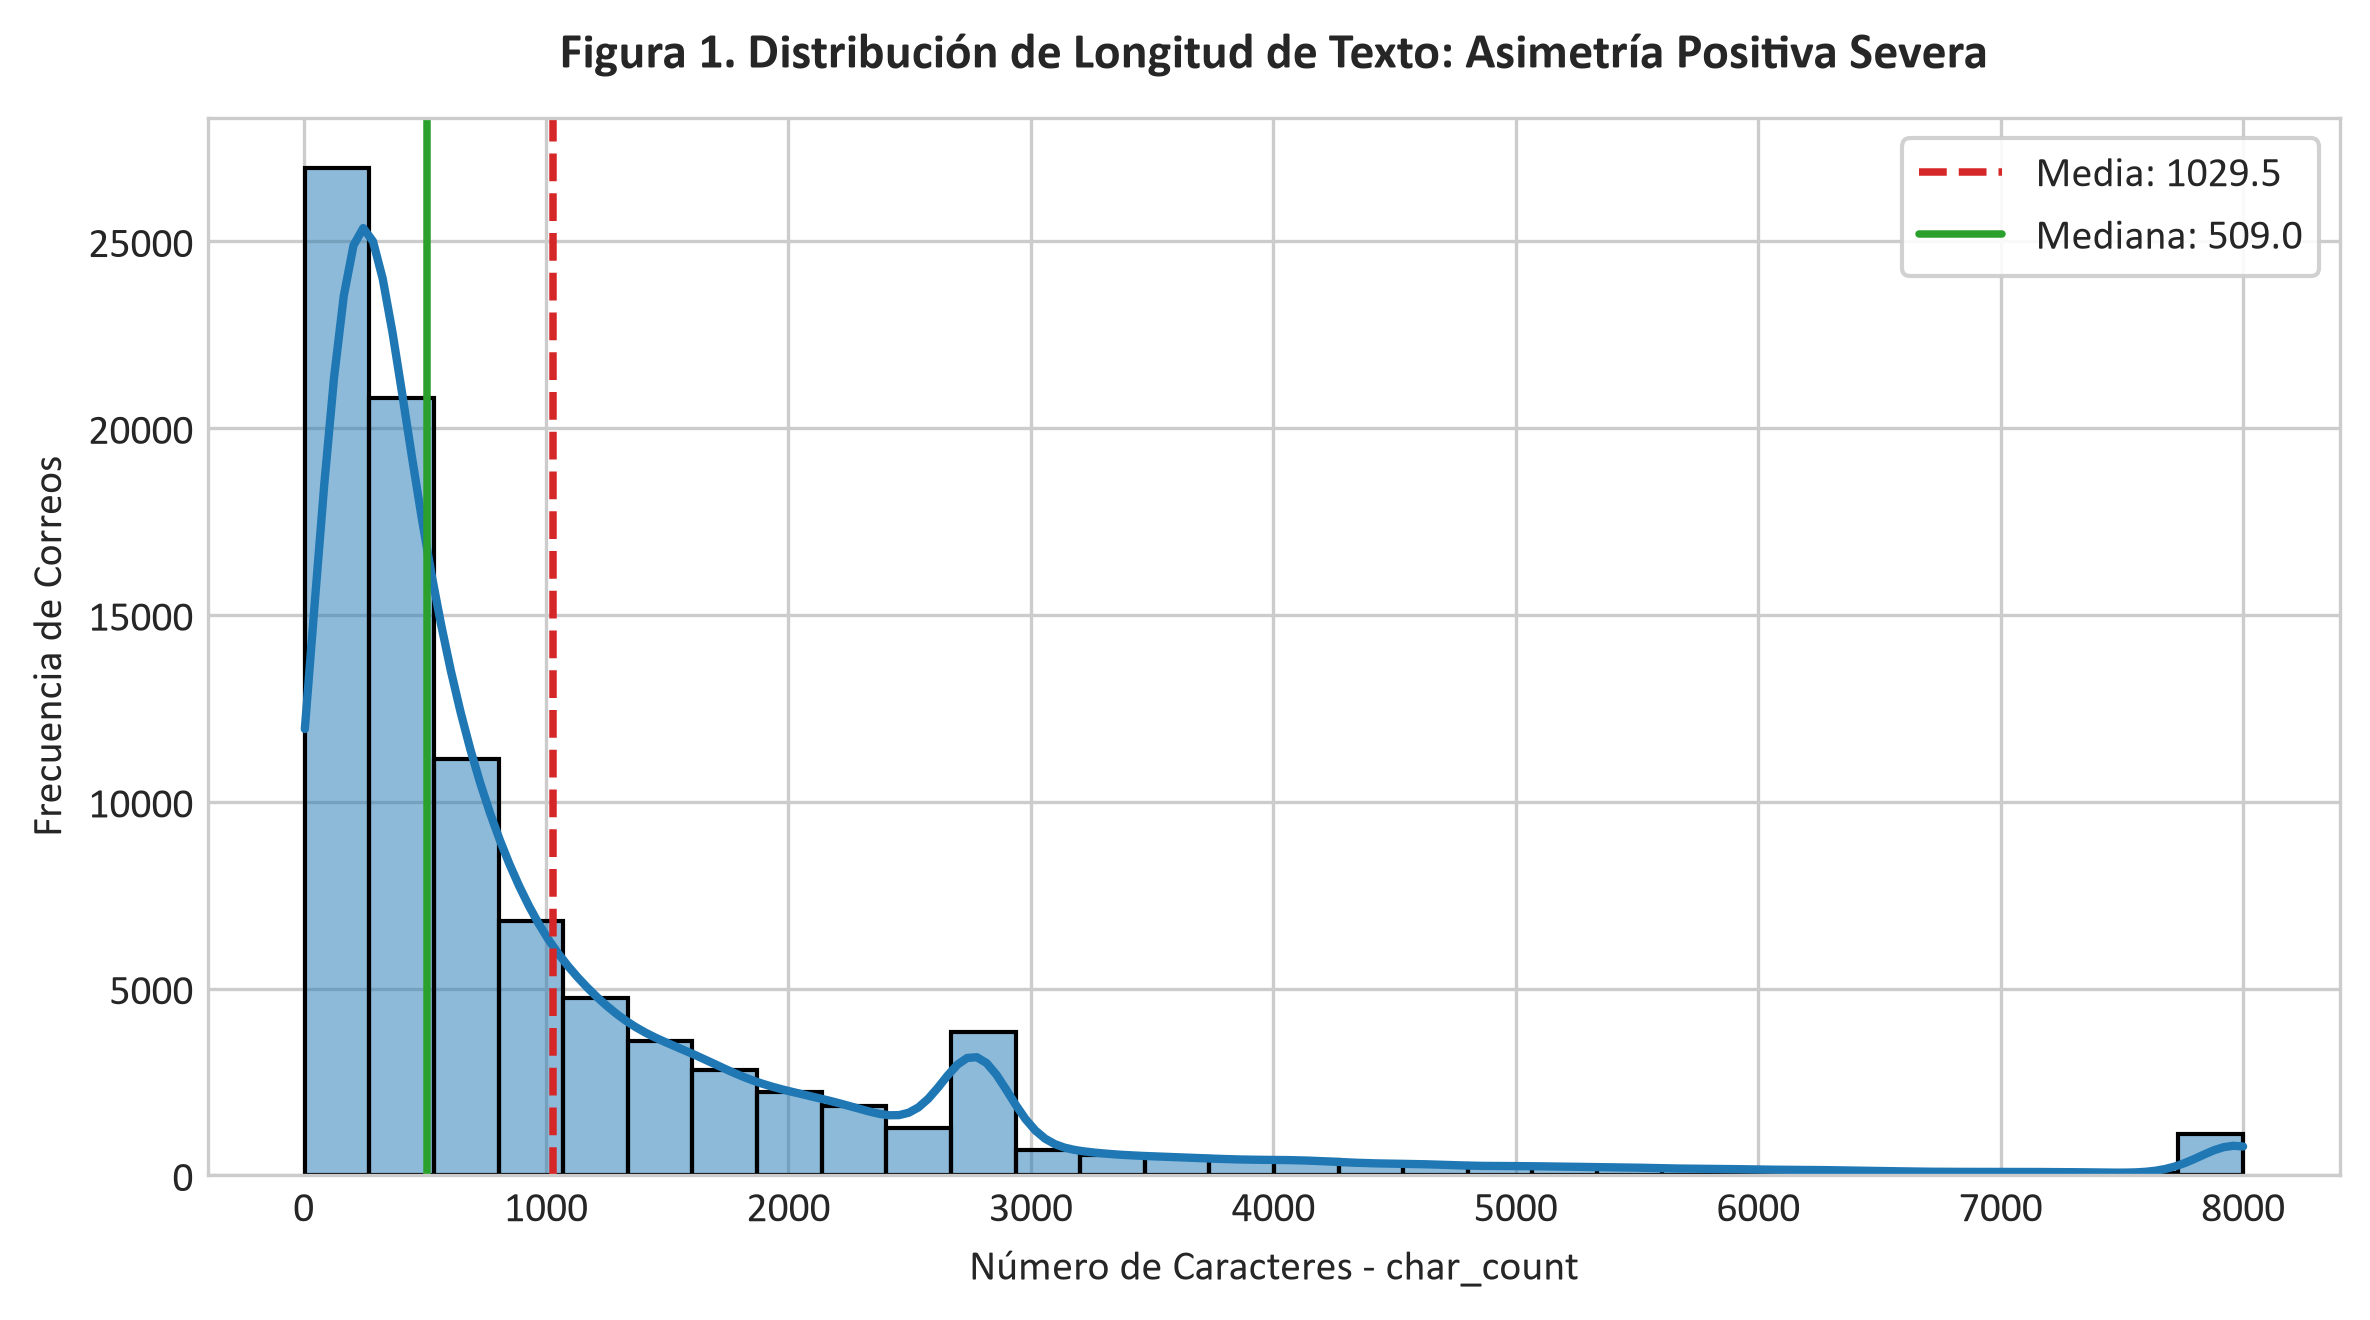

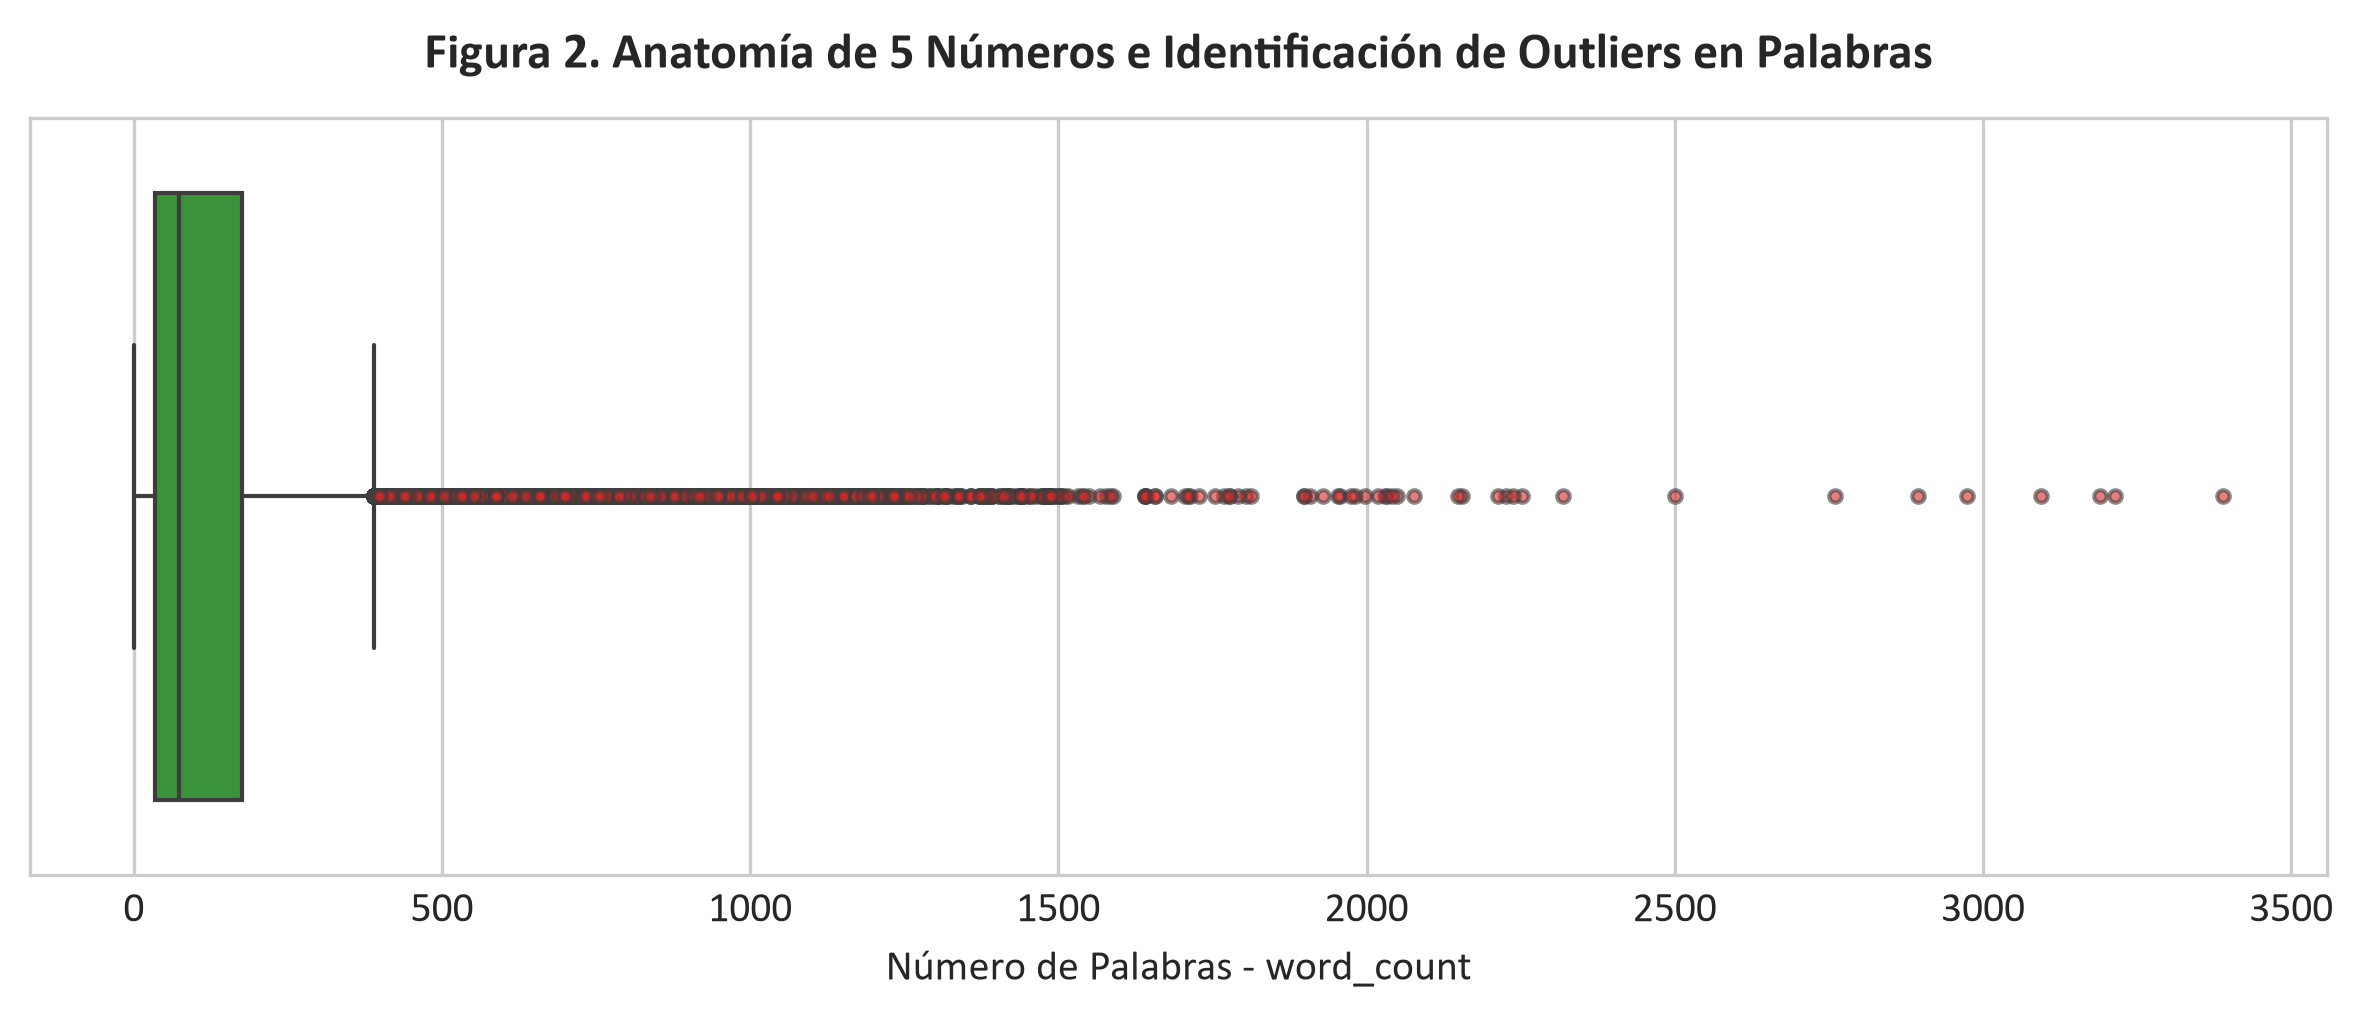

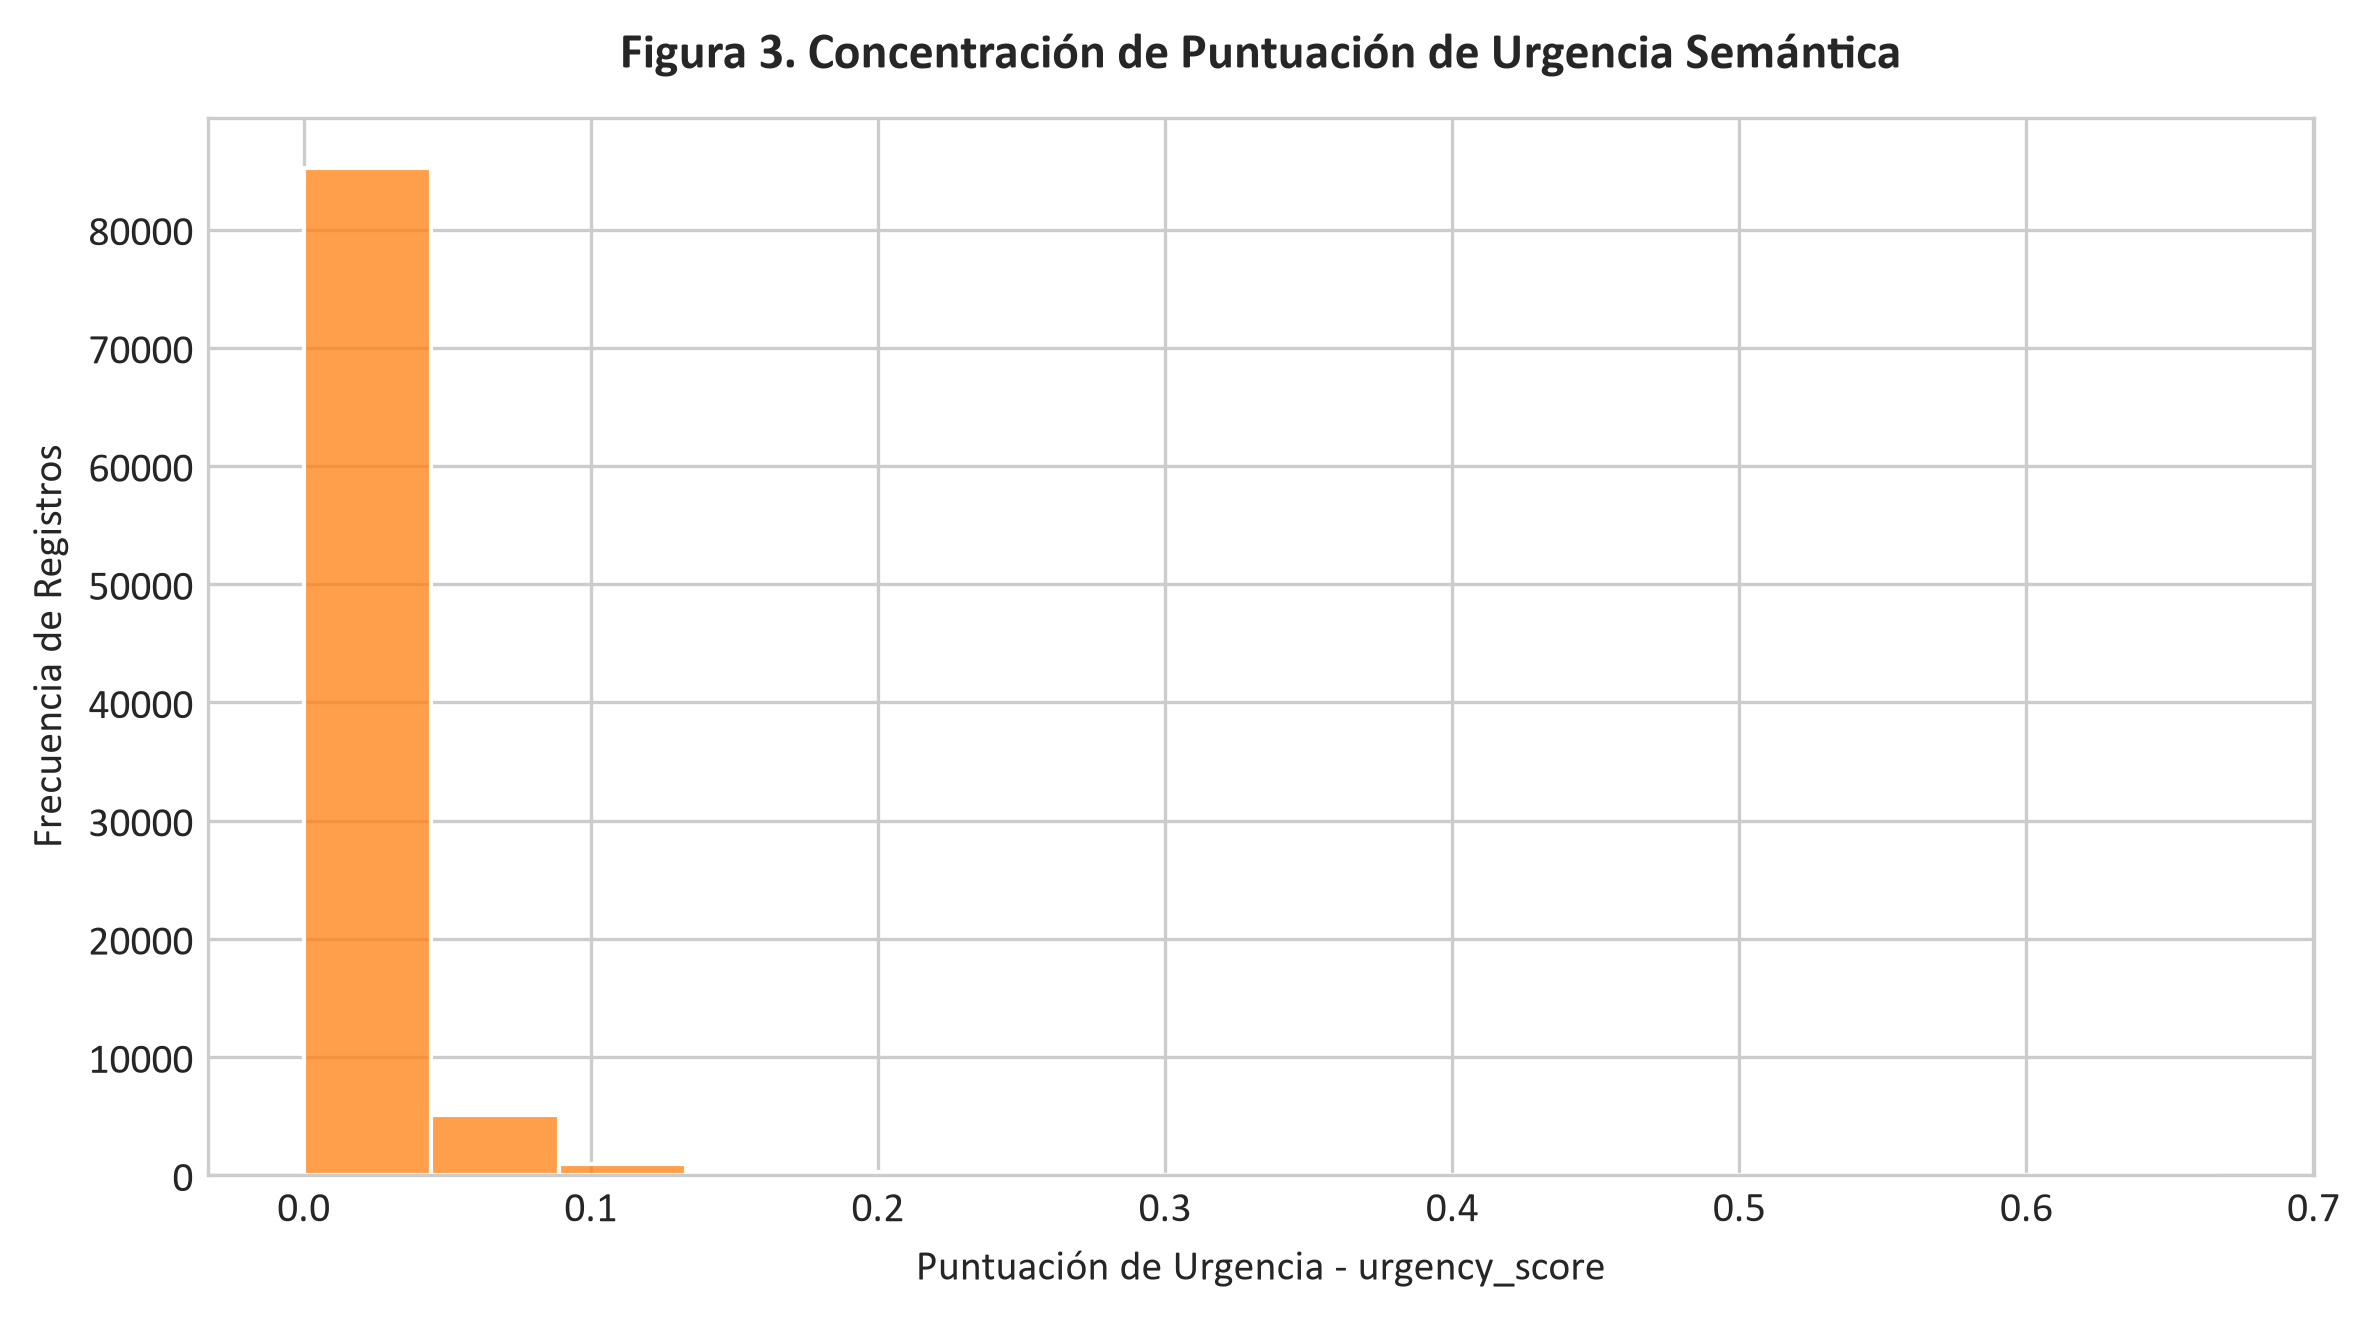

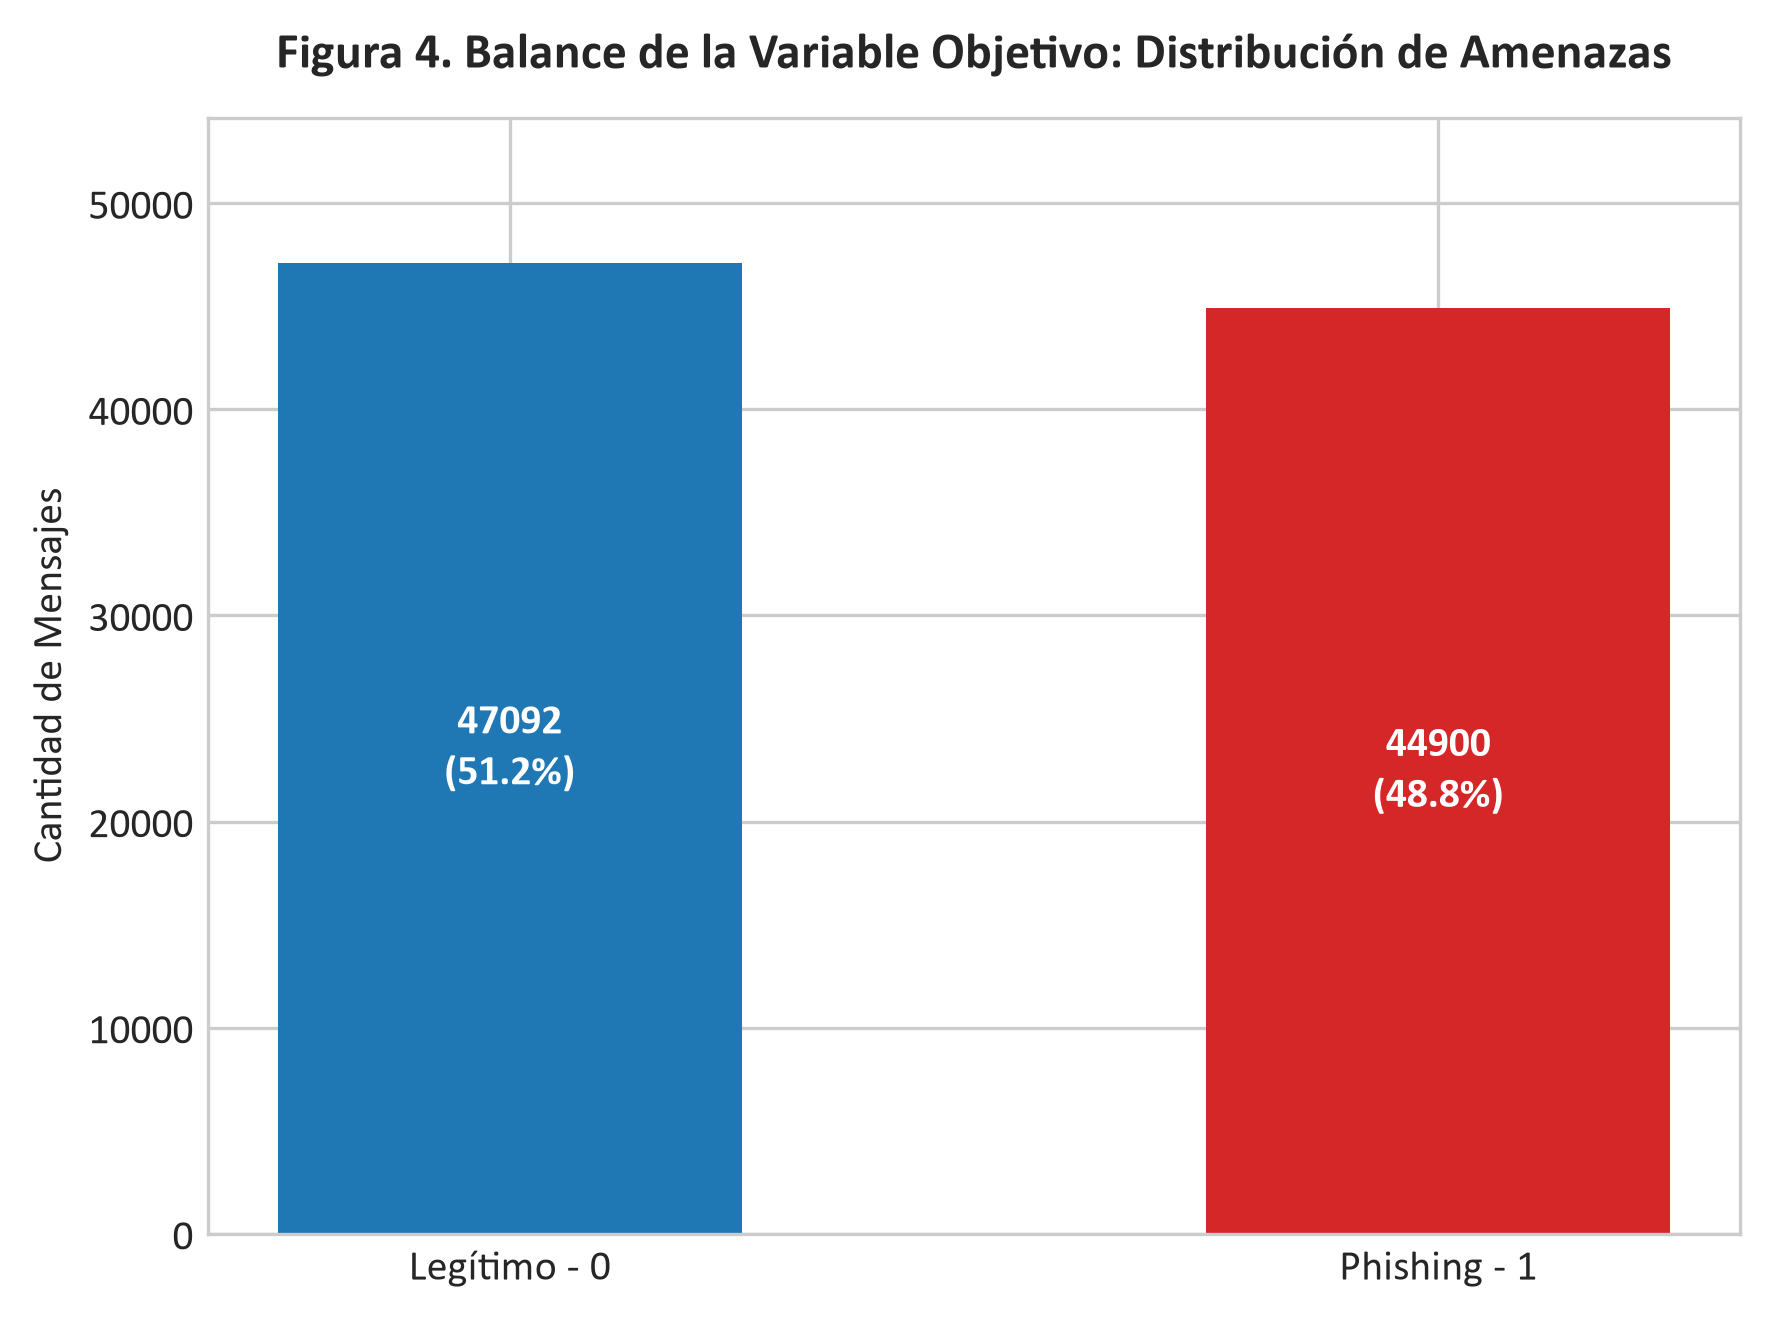

Ejecución completada sin advertencias.


In [3]:
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.sans-serif'] = 'Calibri'
plt.rcParams['axes.edgecolor'] = '#cccccc'
plt.rcParams['axes.linewidth'] = 0.8

os.makedirs('reports/figures', exist_ok=True)

# 1. Cargar el dataset
df = pd.read_csv('../data/processed/clean_dataset.csv')

# ==========================================
# FIGURA 1: HISTOGRAMA + KDE (char_count)
# ==========================================
fig, ax = plt.subplots(figsize=(8, 4.5), dpi=300)

# Usar el dataframe explícito en 'data' y el nombre de la columna en 'x' elimina la alerta de Pylance
sns.histplot(
    data=df,
    x='char_count',
    kde=True,
    color='#1f77b4',
    bins=30,
    ax=ax,
    line_kws={'linewidth': 2},
)

media_char = float(df['char_count'].mean())
mediana_char = float(df['char_count'].median())

ax.axvline(
    media_char,
    color='#d62728',
    linestyle='--',
    linewidth=1.8,
    label=f'Media: {media_char:.1f}',
)
ax.axvline(
    mediana_char,
    color='#2ca02c',
    linestyle='-',
    linewidth=1.8,
    label=f'Mediana: {mediana_char:.1f}',
)

ax.set_title(
    'Figura 1. Distribución de Longitud de Texto: Asimetría Positiva Severa',
    fontsize=12,
    pad=12,
    fontweight='bold',
)
ax.set_xlabel('Número de Caracteres - char_count', fontsize=10)
ax.set_ylabel('Frecuencia de Correos', fontsize=10)
ax.legend(frameon=True, facecolor='white', framealpha=0.9)

plt.tight_layout()
plt.savefig('reports/figures/fig1_hist_char_count.png')
plt.show()

# ==========================================
# FIGURA 2: BOXPLOT (word_count)
# ==========================================
fig, ax = plt.subplots(figsize=(8, 3.5), dpi=300)

sns.boxplot(
    data=df,
    x='word_count',
    color='#2ca02c',
    ax=ax,
    fliersize=3,
    flierprops={'markerfacecolor': '#d62728', 'alpha': 0.6},
)

ax.set_title(
    'Figura 2. Anatomía de 5 Números e Identificación de Outliers en Palabras',
    fontsize=12,
    pad=12,
    fontweight='bold',
)
ax.set_xlabel('Número de Palabras - word_count', fontsize=10)

plt.tight_layout()
plt.savefig('reports/figures/fig2_box_word_count.png')
plt.show()


# ==========================================
# FIGURA 3 CORREGIDA: HISTOGRAMA DE URGENCIA (urgency_score)
# ==========================================
fig, ax = plt.subplots(figsize=(8, 4.5), dpi=300)

# Usar histplot para agrupar los valores continuos
sns.histplot(
    data=df,
    x='urgency_score',
    bins=15,
    color='#ff7f0e',
    ax=ax,
    edgecolor='white',
)

ax.set_title(
    'Figura 3. Concentración de Puntuación de Urgencia Semántica',
    fontsize=12,
    pad=12,
    fontweight='bold',
)
ax.set_xlabel('Puntuación de Urgencia - urgency_score', fontsize=10)
ax.set_ylabel('Frecuencia de Registros', fontsize=10)

plt.tight_layout()
plt.savefig('reports/figures/fig3_bar_urgency.png', dpi=300, bbox_inches='tight')
plt.show()


# ==========================================
# FIGURA 4: BARRAS DE CLASE OBJETIVO (is_threat)
# ==========================================
fig, ax = plt.subplots(figsize=(6, 4.5), dpi=300)
clase_counts = df['is_threat'].value_counts().sort_index()

categorias = ['Legítimo - 0', 'Phishing - 1']
y_clase = [float(v) for v in clase_counts.values]

bars = ax.bar(categorias, y_clase, color=['#1f77b4', '#d62728'], width=0.5)

total = float(len(df))
for bar in bars:
    height = bar.get_height()
    porcentaje = (height / total) * 100
    ax.text(
        bar.get_x() + bar.get_width() / 2.0,
        height / 2,
        f'{int(height)}\n({porcentaje:.1f}%)',
        ha='center',
        va='center',
        color='white',
        fontweight='bold',
        fontsize=10,
    )

ax.set_title(
    'Figura 4. Balance de la Variable Objetivo: Distribución de Amenazas',
    fontsize=12,
    pad=12,
    fontweight='bold',
)
ax.set_ylabel('Cantidad de Mensajes', fontsize=10)
ax.set_ylim(0, max(y_clase) * 1.15)

plt.tight_layout()
plt.savefig('reports/figures/fig4_bar_is_threat.png')
plt.show()

print('Ejecución completada sin advertencias.')